# Tests if "classical" water segmentation might work, too

In [1]:
# modules
import os
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import dask
import dask.array
# from scipy import ndimage
# from skimage import filters, feature, io
# from skimage.morphology import disk,ball
# import sys
# from itertools import combinations_with_replacement
# import pickle
# import imageio
import json
from dask.distributed import Client, LocalCluster

# Workaround that dask does not kill workers while they are busy fetching data: https://dask.discourse.group/t/dask-workers-killed-because-of-heartbeat-fail/856
# maybe this helps: https://www.youtube.com/watch?v=vF2VItVU5zg?
from dask import config as cfg
cfg.set({'distributed.scheduler.worker-ttl': None})

# get the ML functions, TODO: make a library once it works
# pytrainpath = '/mpc/homes/fische_r/lib/pytrainseg'
# cwd = os.getcwd()
# os.chdir(pytrainpath)
# from filter_functions import image_filter
# import training_functions as tfs
# from training_functions import train_segmentation
# from segmentation import segmentation
# os.chdir(cwd)

#paths
import socket
import subprocess
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
else:
    print('currently only host mpc2959.psi.ch supported')
    
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
tempfolder = temppath  #a big SSD is a major adavantage to allow spill to disk and still be efficient. large dataset might crash with too small SSD or be slow with normal HDD
# tempfolder = temppath_2
dask.config.config['temporary-directory'] = tempfolder

# here you have the option to use a virtual cluster or even slurm on ra (not attempted yet)
cluster = LocalCluster(memory_limit = '60GB', n_workers=4, threads_per_worker=20) #settings optimised for mpc2959, play around if needed, 
client = Client(cluster)
print('Dashboard at '+cluster.dashboard_link)

Dashboard at http://127.0.0.1:8787/status


In [3]:
sample = '4'
file = '02_'+sample+'_registered_3p1D.nc'
imagepath = os.path.join(path_02_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()
t_utc = data['t_utc'].data
time = data['time'].data

In [4]:
# with obtained cropping data
# a = 0
# b = -1
# c = 250
# d = -250
# e = 50
# f = -50
jsonpath = os.path.join(training_path, 'cathode_cropping_and_aligning.json')
crop_dict = json.load(open(jsonpath, 'r'))

(a,b,c,d) = crop_dict[sample]
(e,f) = (500,-500)
c = 250
a = a+100
b = b-100

shp = data[images[4]][a:b, c:d, e:f].shape
shp = shp + (len(images),)

In [5]:
shp

(550, 130, 1016, 71)

In [6]:
im = np.zeros(shp, dtype = np.uint16)


In [7]:
# with obtained cropping data
for i in range(shp[-1]):
    im[...,i] = data[images[i]][a:b, c:d, e:f].data

In [8]:
da = dask.array.from_array(im, chunks = 'auto')

In [9]:
da

dask.array<array, shape=(550, 130, 1016, 71), dtype=uint16, chunksize=(98, 98, 98, 71), chunktype=numpy.ndarray>

In [10]:
del im

In [11]:
data.close()

In [20]:
from skimage import filters

In [21]:
def Gaussian_Blur_4D(da, sigma):
    # TODO: check on boundary mode
    deptharray = np.ones(da.ndim)+4*sigma
    deptharray = tuple(np.min([deptharray, da.shape], axis=0))
    G = da.map_overlap(filters.gaussian, depth=deptharray, boundary='nearest', sigma = sigma)
    return G

In [22]:
G = Gaussian_Blur_4D(da, 2)

In [25]:
G = G.compute()

2023-02-21 09:07:09,231 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 39.42 GiB -- Worker memory limit: 55.88 GiB
2023-02-21 09:07:09,316 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 39.36 GiB -- Worker memory limit: 55.88 GiB
2023-02-21 09:07:09,416 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. 

In [23]:
minimum = da.min(axis=-1).compute()

In [24]:
maximum = da.min(axis=-1).compute()

In [27]:
min_gauss = G.min(axis=-1)

In [28]:
ref_min = da - minimum[...,None]
ref_min_gauss = G - min_gauss[...,None]
ref_min_gauss2 = da - min_gauss[...,None]

In [29]:
test = ref_min[:,40,:,64].compute()

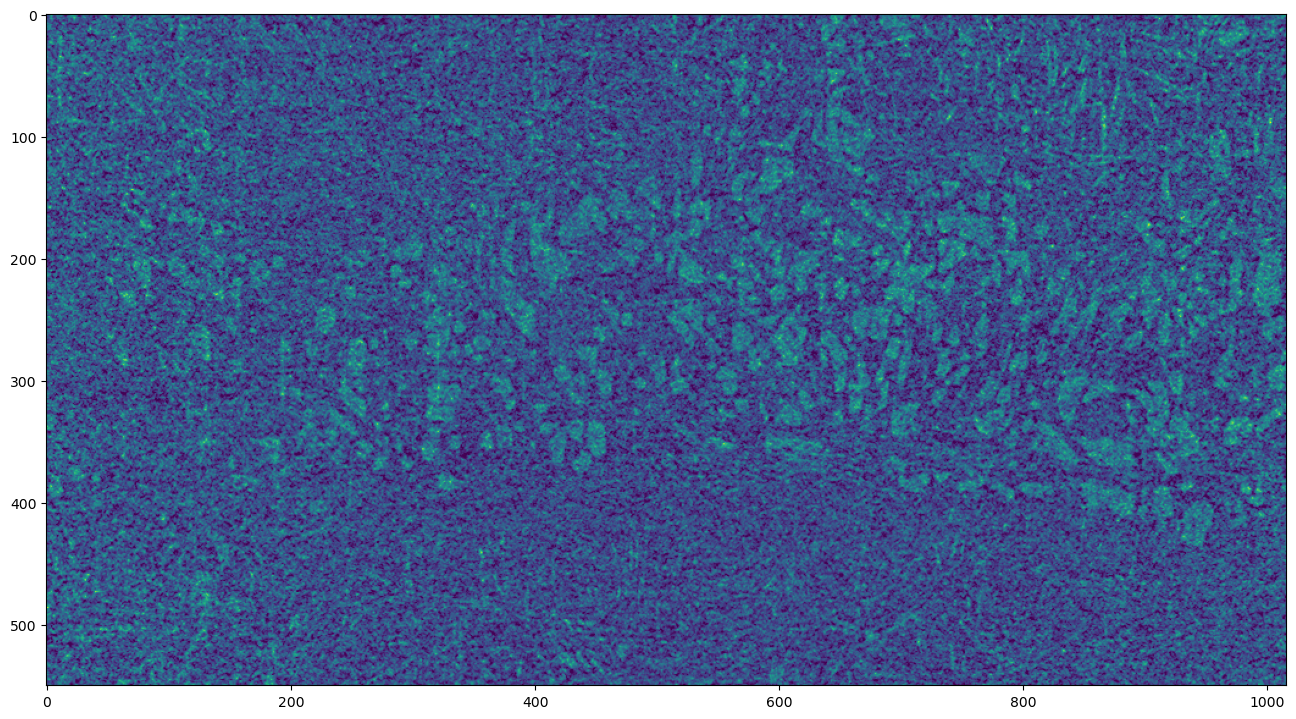

In [30]:
plt.figure(figsize=(16,9))
plt.imshow(test)

In [32]:
test2 = ref_min_gauss[:,40,:,64]
test3 = ref_min_gauss2[:,40,:,64].compute()

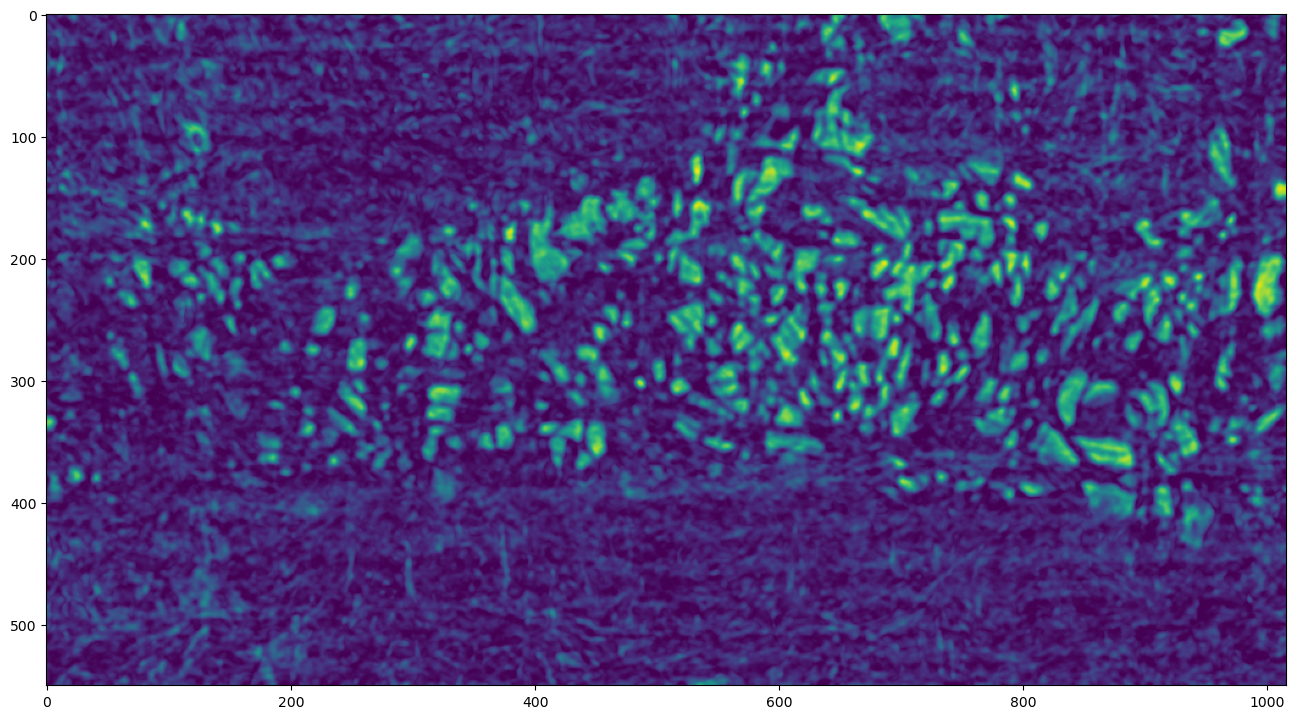

In [33]:
plt.figure(figsize=(16,9))
plt.imshow(test2)

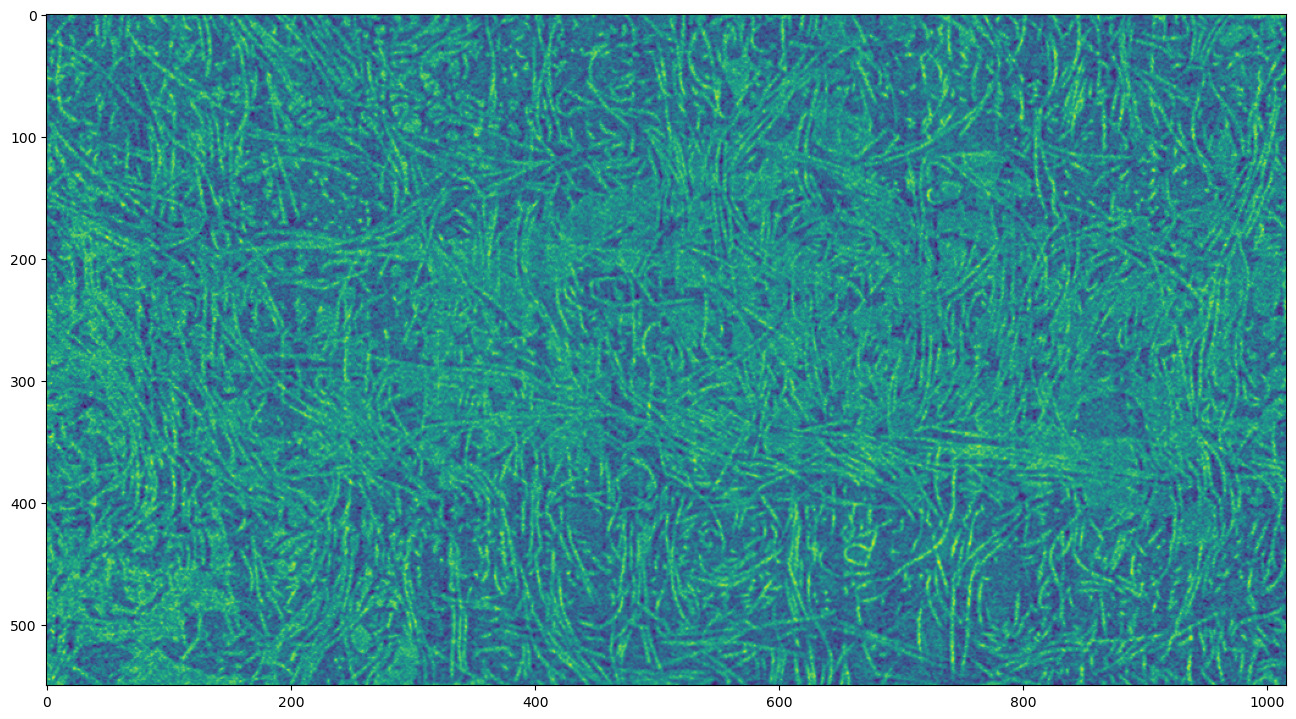

In [34]:
plt.figure(figsize=(16,9))
plt.imshow(test3)